In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import LabelEncoder

# Reload the already-processed/scored datasets directly
df_demo_full = pd.read_csv("tsa_data/demonetization_scored.csv", encoding='latin1')
df_covid_full = pd.read_csv("tsa_data/covid_scored.csv", encoding='latin1')

df_demo_full = df_demo_full.dropna(subset=['processed_text', 'polarity'])
df_covid_full = df_covid_full.dropna(subset=['processed_text', 'polarity'])

print("Demo:", df_demo_full.shape)
print("Covid:", df_covid_full.shape)

Demo: (14912, 21)
Covid: (143479, 23)


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import LabelEncoder

df_demo_full = pd.read_csv("tsa_data/demonetization_scored.csv", encoding='latin1')
df_covid_full = pd.read_csv("tsa_data/covid_scored.csv", encoding='latin1')

df_demo_full = df_demo_full.dropna(subset=['processed_text', 'polarity'])
df_covid_full = df_covid_full.dropna(subset=['processed_text', 'polarity'])

print("Demo:", df_demo_full.shape)
print("Covid:", df_covid_full.shape)

Demo: (14912, 21)
Covid: (143479, 23)


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Reload with clear column selection ---
df_demo = pd.read_csv("demonetization-tweets.csv", encoding='latin1')
df_demo = df_demo.drop(columns=['Unnamed: 0'], errors='ignore')  # drop stray index column

df_covid = pd.read_csv("Covid-19 Twitter Dataset (Apr-Jun 2020).csv", encoding='latin1')

# ============================================================
# 1. Missing values
# ============================================================
print("=== Missing values: Demonetization ===")
print(df_demo.isnull().sum())
print("\n=== Missing values: COVID-19 ===")
print(df_covid.isnull().sum())

# ============================================================
# 2. Duplicate records
# ============================================================
print("\nDuplicate rows (Demonetization):", df_demo.duplicated(subset=['text']).sum())
print("Duplicate rows (COVID-19):", df_covid.duplicated(subset=['original_text']).sum())

# ============================================================
# 3. Tweet length distribution (character count)
# ============================================================
df_demo['char_len'] = df_demo['text'].astype(str).str.len()
df_covid['char_len'] = df_covid['original_text'].astype(str).str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_demo['char_len'], bins=40, color='steelblue')
axes[0].set_title('Demonetization: Tweet Character Length')
axes[0].set_xlabel('Characters')
axes[0].set_ylabel('Number of Tweets')

axes[1].hist(df_covid['char_len'], bins=40, color='indianred')
axes[1].set_title('COVID-19: Tweet Character Length')
axes[1].set_xlabel('Characters')
axes[1].set_ylabel('Number of Tweets')
plt.tight_layout()
plt.show()

# ============================================================
# 4. Word count distribution
# ============================================================
df_demo['word_count'] = df_demo['text'].astype(str).str.split().apply(len)
df_covid['word_count'] = df_covid['original_text'].astype(str).str.split().apply(len)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_demo['word_count'], bins=30, color='steelblue')
axes[0].set_title('Demonetization: Word Count per Tweet')
axes[0].set_xlabel('Words')
axes[0].set_ylabel('Number of Tweets')

axes[1].hist(df_covid['word_count'], bins=30, color='indianred')
axes[1].set_title('COVID-19: Word Count per Tweet')
axes[1].set_xlabel('Words')
axes[1].set_ylabel('Number of Tweets')
plt.tight_layout()
plt.show()

# ============================================================
# 5. Dataset size summary
# ============================================================
print(f"\nDemonetization: {df_demo.shape[0]} tweets, {df_demo.shape[1]} columns")
print(f"COVID-19: {df_covid.shape[0]} tweets, {df_covid.shape[1]} columns")

FileNotFoundError: [Errno 2] No such file or directory: 'demonetization-tweets.csv'

Top 20 words - Demonetization:
  u: 14626
  demonetization: 14570
  rt: 11060
  to: 7728
  t: 6882
  https: 6526
  co: 5703
  ed: 5550
  is: 5370
  the: 5137
  in: 4720
  of: 4112
  s: 3648
  modi: 3102
  india: 3035
  and: 2909
  on: 2835
  that: 2785
  pm: 2739
  a: 2410

Top 20 words - COVID-19:
  the: 97623
  rt: 89208
  t: 82399
  covid: 82287
  https: 75557
  co: 73818
  to: 69330
  of: 56453
  in: 44302
  a: 39538
  and: 38145
  for: 29615
  is: 29606
  s: 23868
  on: 21029
  are: 17795
  with: 15803
  that: 15376
  this: 14989
  we: 14590

Top 15 hashtags - Demonetization:
  #demonetization: 8652
  #india: 378
  #nitishkumar: 258
  #demo: 180
  #glvmi: 145
  #blackmoney: 121
  #corruptionfreeindia: 103
  #modi: 97
  #vijaymallya: 87
  #demonetisation: 86
  #indiafightscorruption: 79
  #bjp: 57
  #demonetizat: 54
  #nomoneyyaar: 53
  #sonunigam: 49

Top 15 hashtags - COVID-19:
  #covid19: 5566
  #covid_19: 4452
  #coronavirus: 1944
  #covid: 1708
  #covid__19: 976
  #covidã: 402

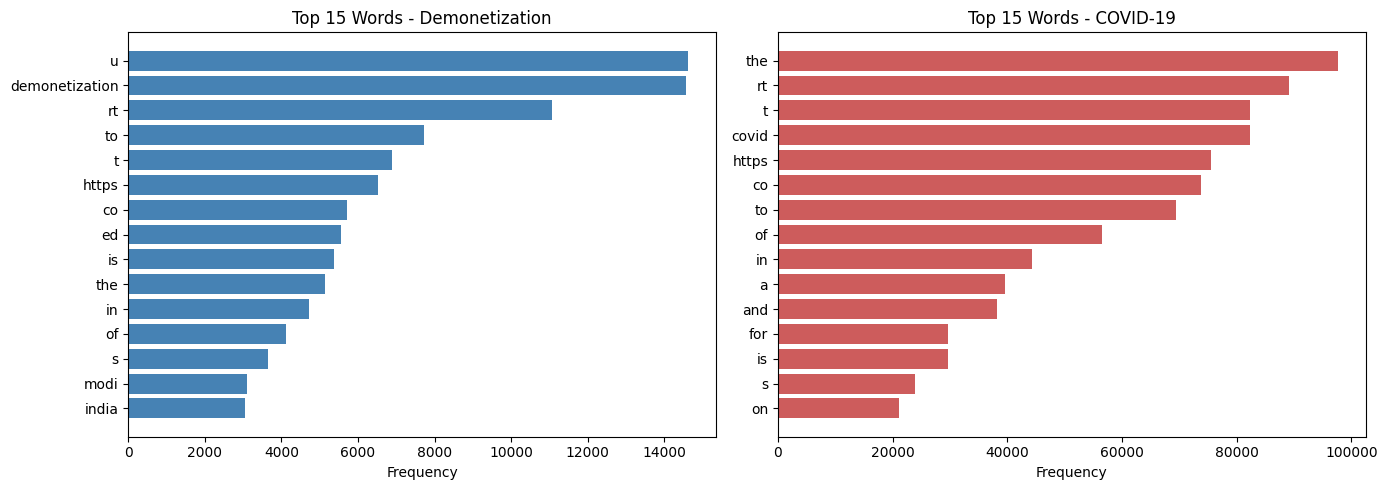

In [ ]:
import re
from collections import Counter
import matplotlib.pyplot as plt

# ============================================================
# 1. Most frequent words (raw, before real preprocessing)
# ============================================================
def get_word_freq(series, top_n=20):
    words = []
    for tweet in series.astype(str):
        tweet = tweet.lower()
        tokens = re.findall(r'\b[a-z]+\b', tweet)  # simple word extraction
        words.extend(tokens)
    return Counter(words).most_common(top_n)

demo_freq = get_word_freq(df_demo['text'])
covid_freq = get_word_freq(df_covid['original_text'])

print("Top 20 words - Demonetization:")
for word, count in demo_freq:
    print(f"  {word}: {count}")

print("\nTop 20 words - COVID-19:")
for word, count in covid_freq:
    print(f"  {word}: {count}")

# ============================================================
# 2. Top hashtags
# ============================================================
def get_hashtags(series, top_n=15):
    tags = []
    for tweet in series.astype(str):
        found = re.findall(r'#(\w+)', tweet)
        tags.extend([t.lower() for t in found])
    return Counter(tags).most_common(top_n)

demo_hashtags = get_hashtags(df_demo['text'])
covid_hashtags = get_hashtags(df_covid['original_text'])

print("\nTop 15 hashtags - Demonetization:")
for tag, count in demo_hashtags:
    print(f"  #{tag}: {count}")

print("\nTop 15 hashtags - COVID-19:")
for tag, count in covid_hashtags:
    print(f"  #{tag}: {count}")

# ============================================================
# 3. Top mentions
# ============================================================
def get_mentions(series, top_n=15):
    mentions = []
    for tweet in series.astype(str):
        found = re.findall(r'@(\w+)', tweet)
        mentions.extend([m.lower() for m in found])
    return Counter(mentions).most_common(top_n)

demo_mentions = get_mentions(df_demo['text'])
covid_mentions = get_mentions(df_covid['original_text'])

print("\nTop 15 mentions - Demonetization:")
for m, count in demo_mentions:
    print(f"  @{m}: {count}")

print("\nTop 15 mentions - COVID-19:")
for m, count in covid_mentions:
    print(f"  @{m}: {count}")

# ============================================================
# 4. Bar chart: top 15 words per dataset
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
words_d, counts_d = zip(*demo_freq[:15])
words_c, counts_c = zip(*covid_freq[:15])

axes[0].barh(words_d[::-1], counts_d[::-1], color='steelblue')
axes[0].set_title('Top 15 Words - Demonetization')
axes[0].set_xlabel('Frequency')

axes[1].barh(words_c[::-1], counts_c[::-1], color='indianred')
axes[1].set_title('Top 15 Words - COVID-19')
axes[1].set_xlabel('Frequency')
plt.tight_layout()
plt.show()

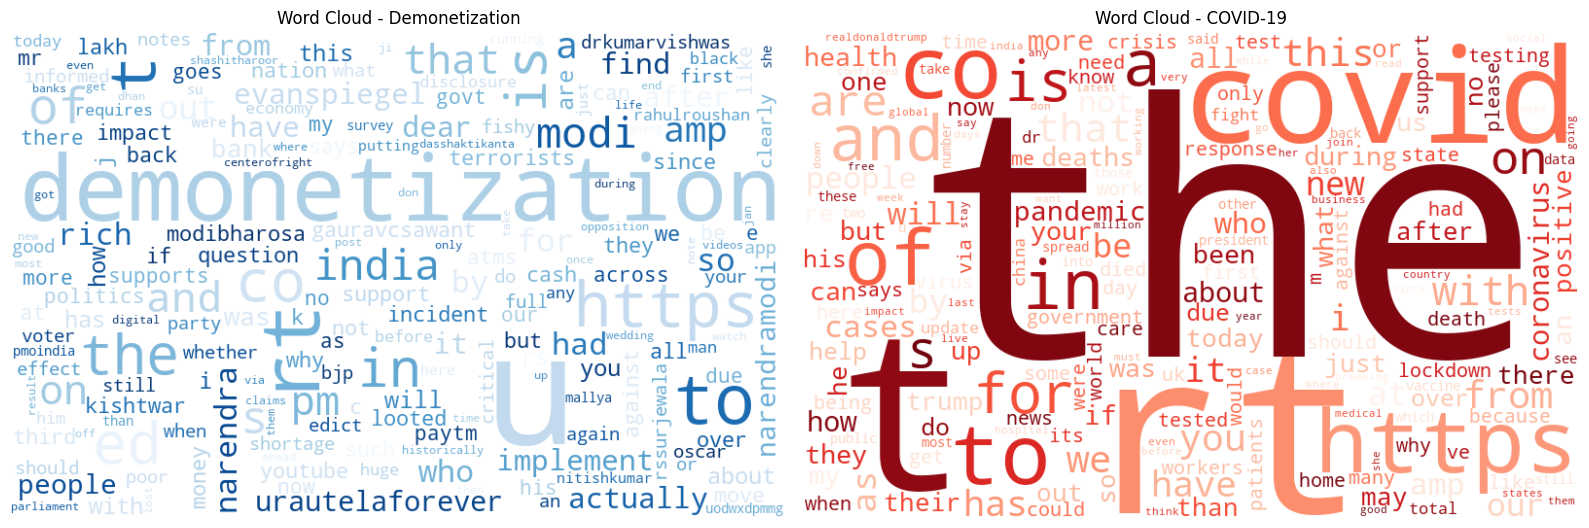

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Build word frequency dicts, excluding obvious URL fragments and RT marker for a cleaner visual
exclude = {'rt', 't', 'co', 'https', 'http'}

def clean_freq_dict(freq_list):
    return {w: c for w, c in freq_list if w not in exclude}

demo_wc_data = clean_freq_dict(demo_freq)
covid_wc_data = clean_freq_dict(covid_freq)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

wc_demo = WordCloud(width=800, height=500, background_color='white', colormap='Blues').generate_from_frequencies(dict(get_word_freq(df_demo['text'], top_n=200)))
wc_covid = WordCloud(width=800, height=500, background_color='white', colormap='Reds').generate_from_frequencies(dict(get_word_freq(df_covid['original_text'], top_n=200)))

axes[0].imshow(wc_demo, interpolation='bilinear')
axes[0].set_title('Word Cloud - Demonetization')
axes[0].axis('off')

axes[1].imshow(wc_covid, interpolation='bilinear')
axes[1].set_title('Word Cloud - COVID-19')
axes[1].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess_tweet(text):
    text = str(text)

    # Step 0 (paper: "remove unwanted and noisy data" / "twitter specific terms")
    text = re.sub(r'^RT\s+', '', text)              # remove leading RT marker
    text = re.sub(r'http\S+|www\S+', '', text)        # remove URLs
    text = re.sub(r'@\w+', '', text)                  # remove mentions
    text = re.sub(r'#(\w+)', r'\1', text)              # keep hashtag word, drop '#'

    # Step 1: Case Conversion
    text = text.lower()

    # Step 2: Punctuation Removal
    text = re.sub(r'[^a-z0-9\s]', '', text)

    # Step 3: Tokenization
    tokens = text.split()

    # Step 4: Stop Word Removal
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]

    # Step 5: Stemming
    tokens = [stemmer.stem(t) for t in tokens]

    return ' '.join(tokens)

# Apply to both datasets
df_demo['processed_text'] = df_demo['text'].apply(preprocess_tweet)
df_covid['processed_text'] = df_covid['original_text'].apply(preprocess_tweet)

# ============================================================
# Before/After table (Phase 7 requirement)
# ============================================================
print("=== Demonetization: Before/After (5 samples) ===")
for i in range(5):
    print(f"\nBEFORE: {df_demo['text'].iloc[i]}")
    print(f"AFTER:  {df_demo['processed_text'].iloc[i]}")

print("\n\n=== COVID-19: Before/After (5 samples) ===")
for i in range(5):
    print(f"\nBEFORE: {df_covid['original_text'].iloc[i]}")
    print(f"AFTER:  {df_covid['processed_text'].iloc[i]}")

# ============================================================
# Record counts before/after + vocabulary size
# ============================================================
# Remove empty tweets after preprocessing
demo_before = len(df_demo)
covid_before = len(df_covid)

df_demo_clean = df_demo[df_demo['processed_text'].str.strip() != ''].copy()
df_covid_clean = df_covid[df_covid['processed_text'].str.strip() != ''].copy()

demo_after = len(df_demo_clean)
covid_after = len(df_covid_clean)

demo_vocab = len(set(' '.join(df_demo_clean['processed_text']).split()))
covid_vocab = len(set(' '.join(df_covid_clean['processed_text']).split()))

print(f"\n\nDemonetization: {demo_before} -> {demo_after} tweets after removing empties. Vocabulary size: {demo_vocab}")
print(f"COVID-19: {covid_before} -> {covid_after} tweets after removing empties. Vocabulary size: {covid_vocab}")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


=== Demonetization: Before/After (5 samples) ===

BEFORE: RT @rssurjewala: Critical question: Was PayTM informed about #Demonetization edict by PM? It's clearly fishy and requires full disclosure &amp;

AFTER:  critic question paytm inform demonet edict pm clearli fishi requir full disclosur amp

BEFORE: RT @Hemant_80: Did you vote on #Demonetization on Modi survey app?
AFTER:  vote demonet modi survey app

BEFORE: RT @roshankar: Former FinSec, RBI Dy Governor, CBDT Chair + Harvard Professor lambaste #Demonetization.

If not for Aam Aadmi, listen to th

AFTER:  former finsec rbi dy governor cbdt chair harvard professor lambast demonet aam aadmi listen th

BEFORE: RT @ANI_news: Gurugram (Haryana): Post office employees provide cash exchange to patients in hospitals #demonetization https://t.co/uGMxUP9

AFTER:  gurugram haryana post offic employe provid cash exchang patient hospit demonet

BEFORE: RT @satishacharya: Reddy Wedding! @mail_today cartoon #demonetization #ReddyWedding http

In [ ]:
def preprocess_tweet(text):
    text = str(text)

    # Step 0: noisy data / twitter-specific terms
    text = re.sub(r'&amp;?', ' ', text)              # NEW: fix HTML-encoded ampersand
    text = re.sub(r'^RT\s+', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#(\w+)', r'\1', text)

    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', '', text)
    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    tokens = [stemmer.stem(t) for t in tokens]
    return ' '.join(tokens)

# Re-apply
df_demo['processed_text'] = df_demo['text'].apply(preprocess_tweet)
df_covid['processed_text'] = df_covid['original_text'].apply(preprocess_tweet)

df_demo_clean = df_demo[df_demo['processed_text'].str.strip() != ''].copy()
df_covid_clean = df_covid[df_covid['processed_text'].str.strip() != ''].copy()

print("Demonetization sample fix check:")
print(df_demo_clean['processed_text'].iloc[0])  # should no longer contain 'amp'

Demonetization sample fix check:
critic question paytm inform demonet edict pm clearli fishi requir full disclosur


In [ ]:
df_demo_clean.to_csv("demonetization_preprocessed.csv", index=False)
df_covid_clean.to_csv("covid_preprocessed.csv", index=False)
print("Saved.")

Saved.


In [ ]:
from afinn import Afinn
import pandas as pd

afinn = Afinn()

# ============================================================
# Inspect the dictionary itself (for your report - Phase 8 requirement)
# ============================================================
print("AFINN dictionary size:", len(afinn._dict))
print("Sample entries:")
sample_words = list(afinn._dict.items())[:10]
for w, r in sample_words:
    print(f"  {w}: {r}")

# ============================================================
# Implement Avg_R exactly as Algorithm 2 describes:
# Avg_R = Sum of word rates / Number of words in tweet
# ============================================================
def compute_avg_r(text):
    tokens = str(text).split()
    if len(tokens) == 0:
        return 0.0
    rates = [afinn.score(word) for word in tokens]  # per-word rate (0 if not in dict)
    return sum(rates) / len(tokens)

def classify_polarity(avg_r):
    if avg_r >= 0.0:
        return 'positive'
    elif avg_r < 0.0:
        return 'negative'
    else:
        return 'neutral'  # unreachable given >= 0 / <0 split, matches paper's own logic gap - see note below

df_demo_clean['avg_r'] = df_demo_clean['processed_text'].apply(compute_avg_r)
df_demo_clean['polarity'] = df_demo_clean['avg_r'].apply(classify_polarity)

df_covid_clean['avg_r'] = df_covid_clean['processed_text'].apply(compute_avg_r)
df_covid_clean['polarity'] = df_covid_clean['avg_r'].apply(classify_polarity)

# ============================================================
# Class distribution (this recreates the paper's Fig. 3!)
# ============================================================
print("\nDemonetization polarity distribution:")
print(df_demo_clean['polarity'].value_counts())

print("\nCOVID-19 polarity distribution:")
print(df_covid_clean['polarity'].value_counts())

df_demo_clean.to_csv("demonetization_scored.csv", index=False)
df_covid_clean.to_csv("covid_scored.csv", index=False)
print("\nSaved scored datasets.")

AFINN dictionary size: 3382
Sample entries:
  abandon: -2
  abandoned: -2
  abandons: -2
  abducted: -2
  abduction: -2
  abductions: -2
  abhor: -3
  abhorred: -3
  abhorrent: -3
  abhors: -3

Demonetization polarity distribution:
polarity
positive    10853
negative     4059
Name: count, dtype: int64

COVID-19 polarity distribution:
polarity
positive    101342
negative     42138
Name: count, dtype: int64

Saved scored datasets.


In [ ]:
# Rebuild a version of preprocessing WITHOUT stemming, specifically for sentiment scoring
def preprocess_for_sentiment(text):
    text = str(text)
    text = re.sub(r'&amp;?', ' ', text)
    text = re.sub(r'^RT\s+', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', '', text)
    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    return ' '.join(tokens)  # NOTE: no stemming here

df_demo_clean['text_for_sentiment'] = df_demo['text'].apply(preprocess_for_sentiment)
df_covid_clean['text_for_sentiment'] = df_covid['original_text'].apply(preprocess_for_sentiment)

def compute_avg_r(text):
    tokens = str(text).split()
    if len(tokens) == 0:
        return 0.0
    rates = [afinn.score(word) for word in tokens]
    return sum(rates) / len(tokens)

def classify_polarity(avg_r):
    if avg_r > 0.0:
        return 'positive'
    elif avg_r < 0.0:
        return 'negative'
    else:
        return 'neutral'   # avg_r == 0.0 exactly (no dictionary words matched, or perfectly balanced)

df_demo_clean['avg_r'] = df_demo_clean['text_for_sentiment'].apply(compute_avg_r)
df_demo_clean['polarity'] = df_demo_clean['avg_r'].apply(classify_polarity)

df_covid_clean['avg_r'] = df_covid_clean['text_for_sentiment'].apply(compute_avg_r)
df_covid_clean['polarity'] = df_covid_clean['avg_r'].apply(classify_polarity)

print("Demonetization polarity distribution:")
print(df_demo_clean['polarity'].value_counts())
print("\nCOVID-19 polarity distribution:")
print(df_covid_clean['polarity'].value_counts())

df_demo_clean.to_csv("demonetization_scored.csv", index=False)
df_covid_clean.to_csv("covid_scored.csv", index=False)
print("\nSaved.")

Demonetization polarity distribution:
polarity
positive    5751
neutral     4933
negative    4228
Name: count, dtype: int64

COVID-19 polarity distribution:
polarity
neutral     49468
negative    49131
positive    44881
Name: count, dtype: int64

Saved.


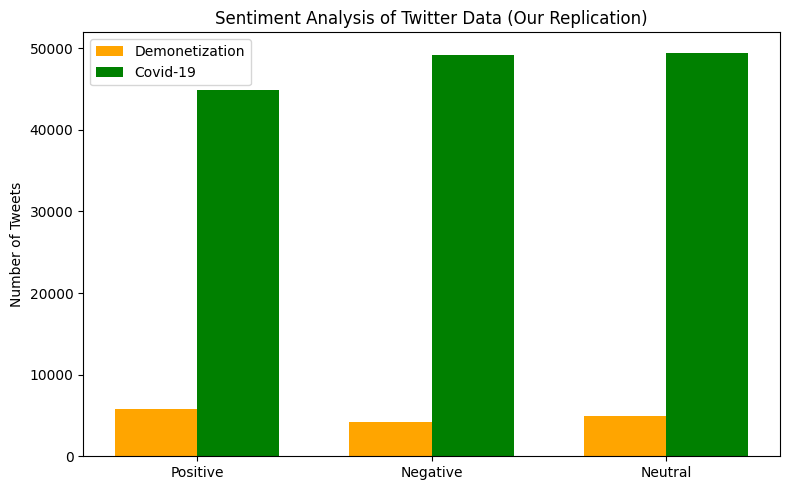

Demonetization: {'positive': 5751, 'neutral': 4933, 'negative': 4228}
Covid-19: {'neutral': 49468, 'negative': 49131, 'positive': 44881}


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

demo_counts = df_demo_clean['polarity'].value_counts()
covid_counts = df_covid_clean['polarity'].value_counts()

categories = ['positive', 'negative', 'neutral']
demo_vals = [demo_counts.get(c, 0) for c in categories]
covid_vals = [covid_counts.get(c, 0) for c in categories]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, demo_vals, width, label='Demonetization', color='orange')
ax.bar(x + width/2, covid_vals, width, label='Covid-19', color='green')

ax.set_xticks(x)
ax.set_xticklabels(['Positive', 'Negative', 'Neutral'])
ax.set_ylabel('Number of Tweets')
ax.set_title('Sentiment Analysis of Twitter Data (Our Replication)')
ax.legend()
plt.tight_layout()
plt.show()

print("Demonetization:", dict(demo_counts))
print("Covid-19:", dict(covid_counts))

In [ ]:
from afinn import Afinn
afinn = Afinn()

# Export the AFINN dictionary as a simple two-column CSV: word, rate
with open("afinn_dictionary.csv", "w", encoding="utf-8") as f:
    for word, rate in afinn._dict.items():
        f.write(f"{word},{rate}\n")

print("Exported", len(afinn._dict), "words to afinn_dictionary.csv")

Exported 3382 words to afinn_dictionary.csv


In [ ]:
from afinn import Afinn
afinn = Afinn()

with open("afinn_dictionary.csv", "w", encoding="utf-8") as f:
    for word, rate in afinn._dict.items():
        f.write(f"{word},{rate}\n")

print("Exported", len(afinn._dict), "words to afinn_dictionary.csv")

Exported 3382 words to afinn_dictionary.csv


In [ ]:
import os
print(os.getcwd())
print(os.path.exists("afinn_dictionary.csv"))

C:\Users\USER\Downloads
True


In [ ]:
import os

print("Current working directory:", os.getcwd())
print("\nFiles in this directory:")
for f in os.listdir():
    if f.endswith('.csv') or f.endswith('.tsv'):
        print(" ", f)

Current working directory: C:\Users\USER\Downloads

Files in this directory:
  attendee_export (2).csv
  attendee_export.csv
  GDGC Nextgen bizchallenge 2026 2026  - Event.csv
  GDGC Science Day 2026  - Event (1).csv
  GDGC Science Day 2026  - Event.csv
  IMDB_NLP_Features.csv
  Lab4_Forecasts.csv
  Lab4_Model_Comparison.csv
  matrix.csv
  NMotsav'26 Master Data - Sheet1.csv
  Plant_1_Generation_Data.csv


In [ ]:
import pandas as pd

df_demo = pd.read_csv("tsa_data/demo_pig_output.tsv", sep='\t', header=None, 
                       names=['id', 'avg_r', 'polarity'])
df_covid = pd.read_csv("tsa_data/covid_scored.csv", encoding='latin1')

print("Demonetization:", df_demo.shape)
print(df_demo['polarity'].value_counts())
print("\nCOVID-19:", df_covid.shape)
print(df_covid['polarity'].value_counts())

Demonetization: (14912, 3)
polarity
positive    5751
neutral     4933
negative    4228
Name: count, dtype: int64

COVID-19: (143480, 23)
polarity
neutral     49468
negative    49131
positive    44881
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# ============================================================
# Prepare features + labels for Demonetization
# We need the processed_text (from Phase 7), not just polarity
# Re-load the preprocessed file which has both processed_text and polarity
# ============================================================
df_demo_full = pd.read_csv("tsa_data/demonetization_scored.csv", encoding='latin1')
df_covid_full = pd.read_csv("tsa_data/covid_scored.csv", encoding='latin1')

print("Demo columns:", df_demo_full.columns.tolist())
print("Demo shape:", df_demo_full.shape)
print("\nCovid columns:", df_covid_full.columns.tolist())
print("Covid shape:", df_covid_full.shape)

# Quick check: does processed_text exist and look right?
print("\nSample processed_text (demo):", df_demo_full['processed_text'].iloc[0])
print("Sample polarity (demo):", df_demo_full['polarity'].iloc[0])

Demo columns: ['X', 'text', 'favorited', 'favoriteCount', 'replyToSN', 'created', 'truncated', 'replyToSID', 'id', 'replyToUID', 'statusSource', 'screenName', 'retweetCount', 'isRetweet', 'retweeted', 'char_len', 'word_count', 'processed_text', 'avg_r', 'polarity', 'text_for_sentiment']
Demo shape: (14912, 21)

Covid columns: ['id', 'created_at', 'source', 'original_text', 'lang', 'favorite_count', 'retweet_count', 'original_author', 'hashtags', 'user_mentions', 'place', 'clean_tweet', 'compound', 'neg', 'neu', 'pos', 'sentiment', 'char_len', 'word_count', 'processed_text', 'avg_r', 'polarity', 'text_for_sentiment']
Covid shape: (143480, 23)

Sample processed_text (demo): critic question paytm inform demonet edict pm clearli fishi requir full disclosur
Sample polarity (demo): positive


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# ============================================================
# Drop rows with missing processed_text (safety check)
# ============================================================
df_demo_full = df_demo_full.dropna(subset=['processed_text', 'polarity'])
df_covid_full = df_covid_full.dropna(subset=['processed_text', 'polarity'])

print("Demo after dropna:", df_demo_full.shape)
print("Covid after dropna:", df_covid_full.shape)

# ============================================================
# TF-IDF vectorization (paper doesn't specify feature method explicitly,
# but classification requires numeric features - TF-IDF is standard choice)
# ============================================================
tfidf_demo = TfidfVectorizer(max_features=5000)
X_demo = tfidf_demo.fit_transform(df_demo_full['processed_text'])
y_demo = df_demo_full['polarity']

tfidf_covid = TfidfVectorizer(max_features=5000)
X_covid = tfidf_covid.fit_transform(df_covid_full['processed_text'])
y_covid = df_covid_full['polarity']

print("\nDemo TF-IDF matrix shape:", X_demo.shape)
print("Covid TF-IDF matrix shape:", X_covid.shape)

# ============================================================
# Train/Test split (paper doesn't state split ratio - using standard 80/20)
# ============================================================
X_demo_train, X_demo_test, y_demo_train, y_demo_test = train_test_split(
    X_demo, y_demo, test_size=0.2, random_state=42, stratify=y_demo)

X_covid_train, X_covid_test, y_covid_train, y_covid_test = train_test_split(
    X_covid, y_covid, test_size=0.2, random_state=42, stratify=y_covid)

print("\nDemo train/test:", X_demo_train.shape, X_demo_test.shape)
print("Covid train/test:", X_covid_train.shape, X_covid_test.shape)

print("\nDemo train class distribution:")
print(y_demo_train.value_counts())
print("\nCovid train class distribution:")
print(y_covid_train.value_counts())

Demo after dropna: (14912, 21)
Covid after dropna: (143479, 23)

Demo TF-IDF matrix shape: (14912, 5000)
Covid TF-IDF matrix shape: (143479, 5000)

Demo train/test: (11929, 5000) (2983, 5000)
Covid train/test: (114783, 5000) (28696, 5000)

Demo train class distribution:
polarity
positive    4601
neutral     3946
negative    3382
Name: count, dtype: int64

Covid train class distribution:
polarity
neutral     39573
negative    39305
positive    35905
Name: count, dtype: int64


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import time

def train_and_evaluate(model, model_name, X_train, y_train, X_test, y_test):
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    
    start = time.time()
    y_pred = model.predict(X_test)
    predict_time = time.time() - start
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=['positive', 'negative', 'neutral'])
    
    print(f"=== {model_name} ===")
    print(f"Accuracy:  {acc*100:.2f}%")
    print(f"Precision: {prec*100:.2f}%")
    print(f"Recall:    {rec*100:.2f}%")
    print(f"F1-Score:  {f1*100:.2f}%")
    print(f"Train time: {train_time:.2f}s | Predict time: {predict_time:.2f}s")
    print(f"Confusion Matrix (rows=actual, cols=pred) [pos, neg, neutral]:\n{cm}")
    print()
    
    return {'model': model_name, 'accuracy': acc*100, 'precision': prec*100, 
            'recall': rec*100, 'f1': f1*100, 'train_time': train_time, 
            'predict_time': predict_time, 'confusion_matrix': cm, 'y_pred': y_pred}

# ============================================================
# DEMONETIZATION dataset
# ============================================================
print("############## DEMONETIZATION ##############\n")

svm_demo = LinearSVC(random_state=42, max_iter=2000)
results_svm_demo = train_and_evaluate(svm_demo, "SVM (Demonetization)", 
                                        X_demo_train, y_demo_train, X_demo_test, y_demo_test)

nb_demo = MultinomialNB()
results_nb_demo = train_and_evaluate(nb_demo, "Naive Bayes (Demonetization)", 
                                       X_demo_train, y_demo_train, X_demo_test, y_demo_test)

# ============================================================
# COVID-19 dataset
# ============================================================
print("############## COVID-19 ##############\n")

svm_covid = LinearSVC(random_state=42, max_iter=2000)
results_svm_covid = train_and_evaluate(svm_covid, "SVM (COVID-19)", 
                                         X_covid_train, y_covid_train, X_covid_test, y_covid_test)

nb_covid = MultinomialNB()
results_nb_covid = train_and_evaluate(nb_covid, "Naive Bayes (COVID-19)", 
                                        X_covid_train, y_covid_train, X_covid_test, y_covid_test)

############## DEMONETIZATION ##############

=== SVM (Demonetization) ===
Accuracy:  94.37%
Precision: 94.36%
Recall:    94.37%
F1-Score:  94.37%
Train time: 0.77s | Predict time: 0.00s
Confusion Matrix (rows=actual, cols=pred) [pos, neg, neutral]:
[[1103   14   33]
 [  16  797   33]
 [  38   34  915]]

=== Naive Bayes (Demonetization) ===
Accuracy:  88.94%
Precision: 89.04%
Recall:    88.94%
F1-Score:  88.96%
Train time: 0.02s | Predict time: 0.00s
Confusion Matrix (rows=actual, cols=pred) [pos, neg, neutral]:
[[1028   30   92]
 [  30  750   66]
 [  62   50  875]]

############## COVID-19 ##############

=== SVM (COVID-19) ===
Accuracy:  87.68%
Precision: 87.63%
Recall:    87.68%
F1-Score:  87.63%
Train time: 3.19s | Predict time: 0.00s
Confusion Matrix (rows=actual, cols=pred) [pos, neg, neutral]:
[[8069  197  710]
 [ 211 8985  630]
 [ 866  922 8106]]

=== Naive Bayes (COVID-19) ===
Accuracy:  75.13%
Precision: 75.23%
Recall:    75.13%
F1-Score:  75.13%
Train time: 0.22s | Predict t

In [ ]:
import pandas as pd

# Collect all results into one summary table
all_results = [results_svm_demo, results_nb_demo, results_svm_covid, results_nb_covid]

summary_df = pd.DataFrame([{
    'Model': r['model'],
    'Accuracy (%)': round(r['accuracy'], 2),
    'Precision (%)': round(r['precision'], 2),
    'Recall (%)': round(r['recall'], 2),
    'F1-Score (%)': round(r['f1'], 2),
    'Train Time (s)': round(r['train_time'], 2)
} for r in all_results])

print(summary_df.to_string(index=False))

                       Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Train Time (s)
        SVM (Demonetization)         94.37          94.36       94.37         94.37            0.77
Naive Bayes (Demonetization)         88.94          89.04       88.94         88.96            0.02
              SVM (COVID-19)         87.68          87.63       87.68         87.63            3.19
      Naive Bayes (COVID-19)         75.13          75.23       75.13         75.13            0.22


In [ ]:
try:
    import tensorflow as tf
    print("TensorFlow version:", tf.__version__)
except ImportError:
    print("TensorFlow NOT installed")

TensorFlow version: 2.19.0


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
import numpy as np

MAX_WORDS = 10000   # vocabulary size cap
MAX_LEN = 30         # max tweet length (in tokens) - matches our earlier EDA (most tweets under 30 words)

def prepare_rnn_data(df, text_col='processed_text', label_col='polarity'):
    texts = df[text_col].astype(str).values
    labels = df[label_col].values
    
    # Tokenize text into integer sequences
    tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
    tokenizer.fit_on_texts(texts)
    sequences = tokenizer.texts_to_sequences(texts)
    X = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')
    
    # Encode labels (positive/negative/neutral -> 0/1/2) and one-hot them
    le = LabelEncoder()
    y_int = le.fit_transform(labels)
    y = to_categorical(y_int)
    
    return X, y, tokenizer, le

# Prepare for both datasets
X_demo_rnn, y_demo_rnn, tok_demo, le_demo = prepare_rnn_data(df_demo_full)
X_covid_rnn, y_covid_rnn, tok_covid, le_covid = prepare_rnn_data(df_covid_full)

print("Demo RNN input shape:", X_demo_rnn.shape, "labels shape:", y_demo_rnn.shape)
print("Covid RNN input shape:", X_covid_rnn.shape, "labels shape:", y_covid_rnn.shape)
print("\nLabel classes (demo):", le_demo.classes_)
print("Label classes (covid):", le_covid.classes_)

# Train/test split (same 80/20, stratified on integer labels)
from sklearn.model_selection import train_test_split

X_demo_rnn_train, X_demo_rnn_test, y_demo_rnn_train, y_demo_rnn_test = train_test_split(
    X_demo_rnn, y_demo_rnn, test_size=0.2, random_state=42, 
    stratify=y_demo_rnn.argmax(axis=1))

X_covid_rnn_train, X_covid_rnn_test, y_covid_rnn_train, y_covid_rnn_test = train_test_split(
    X_covid_rnn, y_covid_rnn, test_size=0.2, random_state=42, 
    stratify=y_covid_rnn.argmax(axis=1))

print("\nDemo train/test:", X_demo_rnn_train.shape, X_demo_rnn_test.shape)
print("Covid train/test:", X_covid_rnn_train.shape, X_covid_rnn_test.shape)

Demo RNN input shape: (14912, 30) labels shape: (14912, 3)
Covid RNN input shape: (143479, 30) labels shape: (143479, 3)

Label classes (demo): ['negative' 'neutral' 'positive']
Label classes (covid): ['negative' 'neutral' 'positive']

Demo train/test: (11929, 30) (2983, 30)
Covid train/test: (114783, 30) (28696, 30)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import time

def build_rnn_model(vocab_size, max_len, num_classes):
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len),
        LSTM(64, dropout=0.2, recurrent_dropout=0.2),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Early stopping: agar validation loss 2 epochs tak improve nahi hoti, training khud ruk jayegi
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

# ============================================================
# DEMONETIZATION RNN
# ============================================================
print("Training RNN on Demonetization dataset...")
rnn_demo = build_rnn_model(vocab_size=MAX_WORDS, max_len=MAX_LEN, num_classes=3)
rnn_demo.summary()

start = time.time()
history_demo = rnn_demo.fit(
    X_demo_rnn_train, y_demo_rnn_train,
    validation_split=0.1,
    epochs=15,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)
demo_rnn_train_time = time.time() - start
print(f"\nDemonetization RNN training time: {demo_rnn_train_time:.2f}s")

Training RNN on Demonetization dataset...


c:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.5928 - loss: 0.8038 - val_accuracy: 0.8567 - val_loss: 0.4049
Epoch 2/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8834 - loss: 0.3651 - val_accuracy: 0.9019 - val_loss: 0.2532
Epoch 3/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9398 - loss: 0.2224 - val_accuracy: 0.9229 - val_loss: 0.2259
Epoch 4/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9660 - loss: 0.1386 - val_accuracy: 0.9237 - val_loss: 0.2246
Epoch 5/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9735 - loss: 0.1138 - val_accuracy: 0.9313 - val_loss: 0.2802
Epoch 6/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9817 - loss: 0.0784 - val_accuracy: 0.9355 - val_loss: 0.2731

Demonetization RNN training time: 19.15s


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def evaluate_rnn(model, X_test, y_test, label_encoder, model_name):
    start = time.time()
    y_pred_probs = model.predict(X_test, verbose=0)
    predict_time = time.time() - start
    
    y_pred = y_pred_probs.argmax(axis=1)
    y_true = y_test.argmax(axis=1)
    
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    
    print(f"=== {model_name} ===")
    print(f"Accuracy:  {acc*100:.2f}%")
    print(f"Precision: {prec*100:.2f}%")
    print(f"Recall:    {rec*100:.2f}%")
    print(f"F1-Score:  {f1*100:.2f}%")
    print(f"Predict time: {predict_time:.2f}s")
    print(f"Confusion Matrix (order: {list(label_encoder.classes_)}):\n{cm}")
    print()
    
    return {'model': model_name, 'accuracy': acc*100, 'precision': prec*100,
            'recall': rec*100, 'f1': f1*100, 'predict_time': predict_time, 
            'confusion_matrix': cm}

# Evaluate Demonetization RNN
results_rnn_demo = evaluate_rnn(rnn_demo, X_demo_rnn_test, y_demo_rnn_test, le_demo, "RNN (Demonetization)")
results_rnn_demo['train_time'] = demo_rnn_train_time

# ============================================================
# COVID-19 RNN (bigger dataset, will take longer)
# ============================================================
print("Training RNN on COVID-19 dataset... (this will take a few minutes)")
rnn_covid = build_rnn_model(vocab_size=MAX_WORDS, max_len=MAX_LEN, num_classes=3)

start = time.time()
history_covid = rnn_covid.fit(
    X_covid_rnn_train, y_covid_rnn_train,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)
covid_rnn_train_time = time.time() - start
print(f"\nCOVID-19 RNN training time: {covid_rnn_train_time:.2f}s")

results_rnn_covid = evaluate_rnn(rnn_covid, X_covid_rnn_test, y_covid_rnn_test, le_covid, "RNN (COVID-19)")
results_rnn_covid['train_time'] = covid_rnn_train_time

=== RNN (Demonetization) ===
Accuracy:  93.03%
Precision: 93.12%
Recall:    93.03%
F1-Score:  93.04%
Predict time: 0.83s
Confusion Matrix (order: ['negative', 'neutral', 'positive']):
[[ 765   64   17]
 [  22  915   50]
 [   9   46 1095]]

Training RNN on COVID-19 dataset... (this will take a few minutes)
Epoch 1/15


c:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


808/808 ━━━━━━━━━━━━━━━━━━━━ 24s 27ms/step - accuracy: 0.6949 - loss: 0.6674 - val_accuracy: 0.8733 - val_loss: 0.3498
Epoch 2/15
808/808 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.8835 - loss: 0.3370 - val_accuracy: 0.8901 - val_loss: 0.3007

COVID-19 RNN training time: 40.43s
=== RNN (COVID-19) ===
Accuracy:  87.49%
Precision: 87.77%
Recall:    87.49%
F1-Score:  87.38%
Predict time: 4.21s
Confusion Matrix (order: ['negative', 'neutral', 'positive']):
[[9321  329  176]
 [1313 7783  798]
 [ 461  512 8003]]



In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Fresh EarlyStopping object, specifically for this training run
early_stop_covid = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

print("Final RNN training on COVID-19 dataset (with fresh EarlyStopping)...")
rnn_covid = build_rnn_model(vocab_size=MAX_WORDS, max_len=MAX_LEN, num_classes=3)

start = time.time()
history_covid = rnn_covid.fit(
    X_covid_rnn_train, y_covid_rnn_train,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop_covid],
    verbose=1
)
covid_rnn_train_time = time.time() - start
print(f"\nCOVID-19 RNN training time: {covid_rnn_train_time:.2f}s")
print(f"Total epochs actually run: {len(history_covid.history['loss'])}")

results_rnn_covid = evaluate_rnn(rnn_covid, X_covid_rnn_test, y_covid_rnn_test, le_covid, "RNN (COVID-19) - Final")
results_rnn_covid['train_time'] = covid_rnn_train_time

Final RNN training on COVID-19 dataset (with fresh EarlyStopping)...
Epoch 1/15
808/808 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.7264 - loss: 0.6263 - val_accuracy: 0.8784 - val_loss: 0.3432
Epoch 2/15
808/808 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8846 - loss: 0.3322 - val_accuracy: 0.8907 - val_loss: 0.2994
Epoch 3/15
808/808 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.8994 - loss: 0.2872 - val_accuracy: 0.8922 - val_loss: 0.3014
Epoch 4/15
808/808 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9073 - loss: 0.2649 - val_accuracy: 0.8928 - val_loss: 0.3105

COVID-19 RNN training time: 56.85s
Total epochs actually run: 4
=== RNN (COVID-19) - Final ===
Accuracy:  89.09%
Precision: 89.20%
Recall:    89.09%
F1-Score:  88.98%
Predict time: 3.28s
Confusion Matrix (order: ['negative', 'neutral', 'positive']):
[[9349  345  132]
 [1080 7944  870]
 [ 238  465 8273]]



In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Fresh EarlyStopping object for Demonetization too, for consistency
early_stop_demo = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

print("Final RNN training on Demonetization dataset (with fresh EarlyStopping)...")
rnn_demo = build_rnn_model(vocab_size=MAX_WORDS, max_len=MAX_LEN, num_classes=3)

start = time.time()
history_demo = rnn_demo.fit(
    X_demo_rnn_train, y_demo_rnn_train,
    validation_split=0.1,
    epochs=15,
    batch_size=64,
    callbacks=[early_stop_demo],
    verbose=1
)
demo_rnn_train_time = time.time() - start
print(f"\nDemonetization RNN training time: {demo_rnn_train_time:.2f}s")
print(f"Total epochs actually run: {len(history_demo.history['loss'])}")

results_rnn_demo = evaluate_rnn(rnn_demo, X_demo_rnn_test, y_demo_rnn_test, le_demo, "RNN (Demonetization) - Final")
results_rnn_demo['train_time'] = demo_rnn_train_time

Final RNN training on Demonetization dataset (with fresh EarlyStopping)...
Epoch 1/15


c:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


168/168 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.5481 - loss: 0.8533 - val_accuracy: 0.8189 - val_loss: 0.5575
Epoch 2/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8502 - loss: 0.4162 - val_accuracy: 0.9128 - val_loss: 0.2662
Epoch 3/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9351 - loss: 0.2242 - val_accuracy: 0.9187 - val_loss: 0.2681
Epoch 4/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9642 - loss: 0.1393 - val_accuracy: 0.9220 - val_loss: 0.2682

Demonetization RNN training time: 13.47s
Total epochs actually run: 4
=== RNN (Demonetization) - Final ===
Accuracy:  91.28%
Precision: 91.46%
Recall:    91.28%
F1-Score:  91.33%
Predict time: 0.79s
Confusion Matrix (order: ['negative', 'neutral', 'positive']):
[[ 765   71   10]
 [  50  899   38]
 [  15   76 1059]]



      Model        Dataset  Accuracy  Precision  Recall    F1
        SVM Demonetization     94.37      94.36   94.37 94.37
Naive Bayes Demonetization     88.94      89.04   88.94 88.96
        RNN Demonetization     91.28      91.46   91.28 91.33
        SVM       COVID-19     87.68      87.63   87.68 87.63
Naive Bayes       COVID-19     75.13      75.23   75.13 75.13
        RNN       COVID-19     89.09      89.20   89.09 88.98


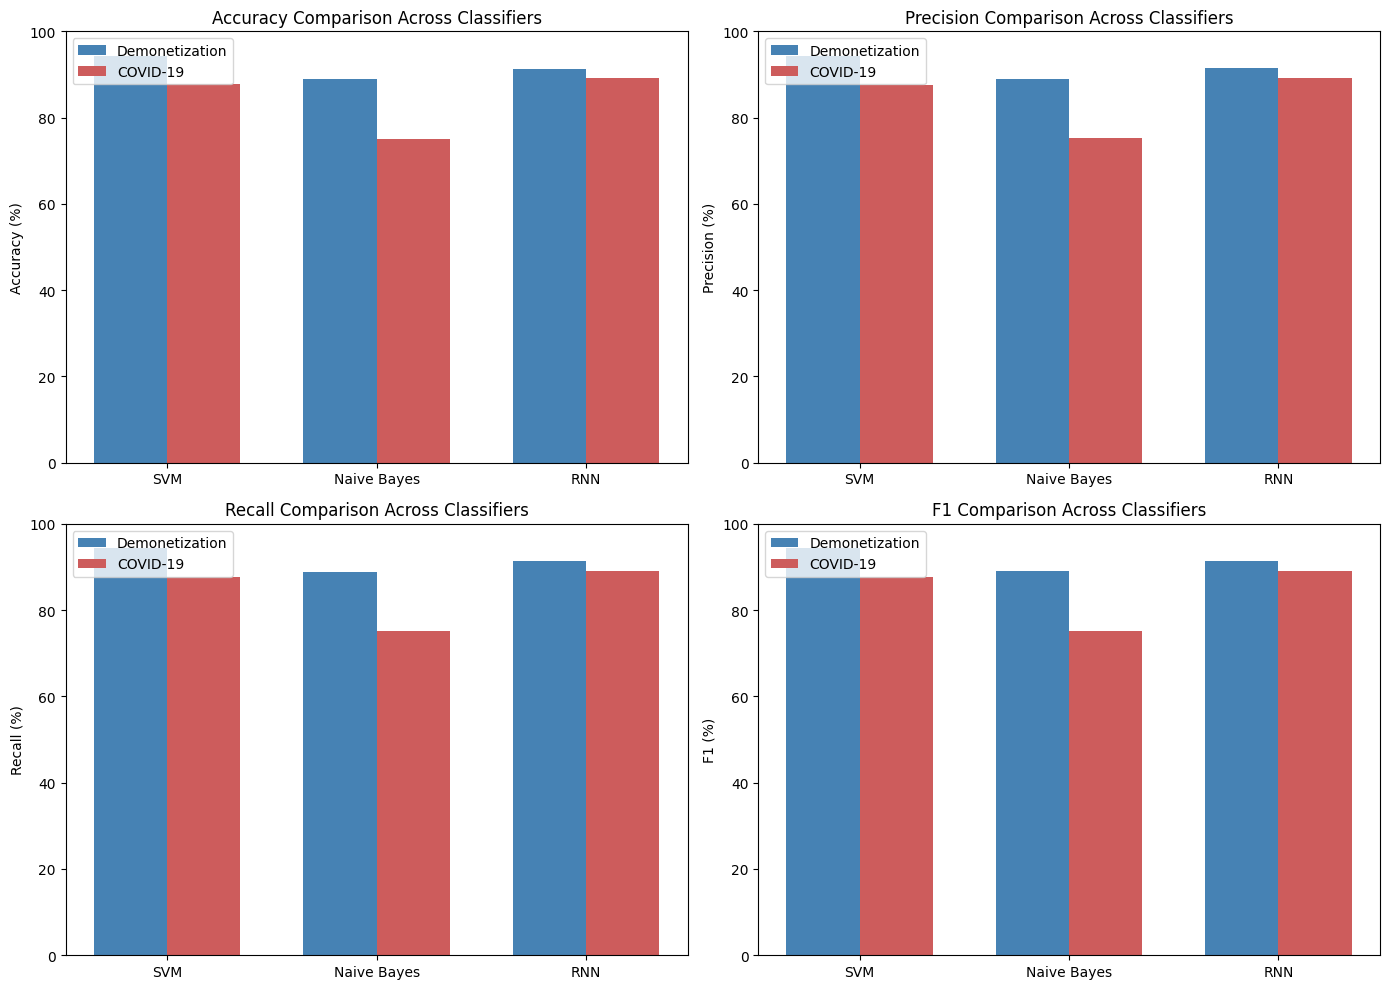

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

all_final_results = [
    results_svm_demo, results_nb_demo, results_rnn_demo,
    results_svm_covid, results_nb_covid, results_rnn_covid
]

final_summary = pd.DataFrame([{
    'Model': r['model'].split(' (')[0].replace(' - Final', ''),
    'Dataset': r['model'].split('(')[1].replace(')', '').replace(' - Final', ''),
    'Accuracy': round(r['accuracy'], 2),
    'Precision': round(r['precision'], 2),
    'Recall': round(r['recall'], 2),
    'F1': round(r['f1'], 2),
} for r in all_final_results])

print(final_summary.to_string(index=False))

metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
models = ['SVM', 'Naive Bayes', 'RNN']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, metric in enumerate(metrics):
    ax = axes[idx]
    x = np.arange(len(models))
    width = 0.35
    
    demo_vals = [final_summary[(final_summary['Model']==m) & (final_summary['Dataset']=='Demonetization')][metric].values[0] for m in models]
    covid_vals = [final_summary[(final_summary['Model']==m) & (final_summary['Dataset']=='COVID-19')][metric].values[0] for m in models]
    
    ax.bar(x - width/2, demo_vals, width, label='Demonetization', color='steelblue')
    ax.bar(x + width/2, covid_vals, width, label='COVID-19', color='indianred')
    
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.set_ylabel(f'{metric} (%)')
    ax.set_title(f'{metric} Comparison Across Classifiers')
    ax.legend()
    ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

In [ ]:
try:
    print(df_demo_full.shape)
except NameError:
    print("df_demo_full NOT in memory - kernel was restarted, need to re-run cells")

df_demo_full NOT in memory - kernel was restarted, need to re-run cells


In [ ]:
# ============================================================
# TF-IDF + Train/Test Split
# ============================================================
tfidf_demo = TfidfVectorizer(max_features=5000)
X_demo = tfidf_demo.fit_transform(df_demo_full['processed_text'])
y_demo = df_demo_full['polarity']

tfidf_covid = TfidfVectorizer(max_features=5000)
X_covid = tfidf_covid.fit_transform(df_covid_full['processed_text'])
y_covid = df_covid_full['polarity']

X_demo_train, X_demo_test, y_demo_train, y_demo_test = train_test_split(
    X_demo, y_demo, test_size=0.2, random_state=42, stratify=y_demo)
X_covid_train, X_covid_test, y_covid_train, y_covid_test = train_test_split(
    X_covid, y_covid, test_size=0.2, random_state=42, stratify=y_covid)

def train_and_evaluate(model, model_name, X_train, y_train, X_test, y_test):
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    start = time.time()
    y_pred = model.predict(X_test)
    predict_time = time.time() - start
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=['positive', 'negative', 'neutral'])
    print(f"=== {model_name} === Acc:{acc*100:.2f}% Prec:{prec*100:.2f}% Rec:{rec*100:.2f}% F1:{f1*100:.2f}% (train {train_time:.2f}s)")
    return {'model': model_name, 'accuracy': acc*100, 'precision': prec*100,
            'recall': rec*100, 'f1': f1*100, 'train_time': train_time,
            'predict_time': predict_time, 'confusion_matrix': cm}

print("### SVM + Naive Bayes ###")
results_svm_demo = train_and_evaluate(LinearSVC(random_state=42, max_iter=2000), "SVM (Demonetization)", X_demo_train, y_demo_train, X_demo_test, y_demo_test)
results_nb_demo = train_and_evaluate(MultinomialNB(), "Naive Bayes (Demonetization)", X_demo_train, y_demo_train, X_demo_test, y_demo_test)
results_svm_covid = train_and_evaluate(LinearSVC(random_state=42, max_iter=2000), "SVM (COVID-19)", X_covid_train, y_covid_train, X_covid_test, y_covid_test)
results_nb_covid = train_and_evaluate(MultinomialNB(), "Naive Bayes (COVID-19)", X_covid_train, y_covid_train, X_covid_test, y_covid_test)

# ============================================================
# RNN prep
# ============================================================
MAX_WORDS = 10000
MAX_LEN = 30

def prepare_rnn_data(df, text_col='processed_text', label_col='polarity'):
    texts = df[text_col].astype(str).values
    labels = df[label_col].values
    tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
    tokenizer.fit_on_texts(texts)
    sequences = tokenizer.texts_to_sequences(texts)
    X = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')
    le = LabelEncoder()
    y_int = le.fit_transform(labels)
    y = to_categorical(y_int)
    return X, y, tokenizer, le

X_demo_rnn, y_demo_rnn, tok_demo, le_demo = prepare_rnn_data(df_demo_full)
X_covid_rnn, y_covid_rnn, tok_covid, le_covid = prepare_rnn_data(df_covid_full)

X_demo_rnn_train, X_demo_rnn_test, y_demo_rnn_train, y_demo_rnn_test = train_test_split(
    X_demo_rnn, y_demo_rnn, test_size=0.2, random_state=42, stratify=y_demo_rnn.argmax(axis=1))
X_covid_rnn_train, X_covid_rnn_test, y_covid_rnn_train, y_covid_rnn_test = train_test_split(
    X_covid_rnn, y_covid_rnn, test_size=0.2, random_state=42, stratify=y_covid_rnn.argmax(axis=1))

def build_rnn_model(vocab_size, max_len, num_classes):
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=64),
        LSTM(64, dropout=0.2, recurrent_dropout=0.2),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def evaluate_rnn(model, X_test, y_test, label_encoder, model_name):
    start = time.time()
    y_pred_probs = model.predict(X_test, verbose=0)
    predict_time = time.time() - start
    y_pred = y_pred_probs.argmax(axis=1)
    y_true = y_test.argmax(axis=1)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    print(f"=== {model_name} === Acc:{acc*100:.2f}% Prec:{prec*100:.2f}% Rec:{rec*100:.2f}% F1:{f1*100:.2f}%")
    return {'model': model_name, 'accuracy': acc*100, 'precision': prec*100,
            'recall': rec*100, 'f1': f1*100, 'predict_time': predict_time, 'confusion_matrix': cm}

print("\n### RNN Demonetization ###")
early_stop_demo = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
rnn_demo = build_rnn_model(MAX_WORDS, MAX_LEN, 3)
start = time.time()
rnn_demo.fit(X_demo_rnn_train, y_demo_rnn_train, validation_split=0.1, epochs=15, batch_size=64, callbacks=[early_stop_demo], verbose=1)
demo_rnn_train_time = time.time() - start
results_rnn_demo = evaluate_rnn(rnn_demo, X_demo_rnn_test, y_demo_rnn_test, le_demo, "RNN (Demonetization)")
results_rnn_demo['train_time'] = demo_rnn_train_time

print("\n### RNN COVID-19 ###")
early_stop_covid = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
rnn_covid = build_rnn_model(MAX_WORDS, MAX_LEN, 3)
start = time.time()
rnn_covid.fit(X_covid_rnn_train, y_covid_rnn_train, validation_split=0.1, epochs=15, batch_size=128, callbacks=[early_stop_covid], verbose=1)
covid_rnn_train_time = time.time() - start
results_rnn_covid = evaluate_rnn(rnn_covid, X_covid_rnn_test, y_covid_rnn_test, le_covid, "RNN (COVID-19)")
results_rnn_covid['train_time'] = covid_rnn_train_time

print("\nAll models trained and evaluated successfully!")

NameError: name 'TfidfVectorizer' is not defined

In [ ]:
# ============================================================
# Confusion matrices - all 6 models, visualized as heatmaps
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

configs = [
    (results_svm_demo, axes[0,0]), (results_nb_demo, axes[0,1]), (results_rnn_demo, axes[0,2]),
    (results_svm_covid, axes[1,0]), (results_nb_covid, axes[1,1]), (results_rnn_covid, axes[1,2])
]

for result, ax in configs:
    cm = result['confusion_matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(result['model'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

# ============================================================
# Build final summary table
# ============================================================
all_final_results = [
    results_svm_demo, results_nb_demo, results_rnn_demo,
    results_svm_covid, results_nb_covid, results_rnn_covid
]

final_summary = pd.DataFrame([{
    'Model': r['model'].split(' (')[0],
    'Dataset': r['model'].split('(')[1].replace(')', ''),
    'Accuracy': round(r['accuracy'], 2),
    'Precision': round(r['precision'], 2),
    'Recall': round(r['recall'], 2),
    'F1': round(r['f1'], 2),
} for r in all_final_results])

final_summary['Error Rate'] = round(100 - final_summary['Accuracy'], 2)
print(final_summary.to_string(index=False))

# ============================================================
# Error rate comparison graph
# ============================================================
models = ['SVM', 'Naive Bayes', 'RNN']
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(models))
width = 0.35

demo_err = [final_summary[(final_summary['Model']==m) & (final_summary['Dataset']=='Demonetization')]['Error Rate'].values[0] for m in models]
covid_err = [final_summary[(final_summary['Model']==m) & (final_summary['Dataset']=='COVID-19')]['Error Rate'].values[0] for m in models]

ax.bar(x - width/2, demo_err, width, label='Demonetization', color='seagreen')
ax.bar(x + width/2, covid_err, width, label='COVID-19', color='gold')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel('Error Rate (%)')
ax.set_title('Error Rate Comparison (paper Fig. 9 equivalent)')
ax.legend()
plt.tight_layout()
plt.show()

# ============================================================
# Training time comparison
# ============================================================
print("\nTraining times (seconds):")
for r in all_final_results:
    print(f"  {r['model']}: {r['train_time']:.2f}s")

NameError: name 'plt' is not defined

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import LabelEncoder

df_demo_full = pd.read_csv("tsa_data/demonetization_scored.csv", encoding='latin1')
df_covid_full = pd.read_csv("tsa_data/covid_scored.csv", encoding='latin1')

df_demo_full = df_demo_full.dropna(subset=['processed_text', 'polarity'])
df_covid_full = df_covid_full.dropna(subset=['processed_text', 'polarity'])

print("Demo:", df_demo_full.shape)
print("Covid:", df_covid_full.shape)

Demo: (14912, 21)
Covid: (143479, 23)


In [12]:
tfidf_demo = TfidfVectorizer(max_features=5000)
X_demo = tfidf_demo.fit_transform(df_demo_full['processed_text'])
y_demo = df_demo_full['polarity']

tfidf_covid = TfidfVectorizer(max_features=5000)
X_covid = tfidf_covid.fit_transform(df_covid_full['processed_text'])
y_covid = df_covid_full['polarity']

X_demo_train, X_demo_test, y_demo_train, y_demo_test = train_test_split(
    X_demo, y_demo, test_size=0.2, random_state=42, stratify=y_demo)
X_covid_train, X_covid_test, y_covid_train, y_covid_test = train_test_split(
    X_covid, y_covid, test_size=0.2, random_state=42, stratify=y_covid)

print("Demo train/test:", X_demo_train.shape, X_demo_test.shape)
print("Covid train/test:", X_covid_train.shape, X_covid_test.shape)

Demo train/test: (11929, 5000) (2983, 5000)
Covid train/test: (114783, 5000) (28696, 5000)


In [13]:
def train_and_evaluate(model, model_name, X_train, y_train, X_test, y_test):
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    start = time.time()
    y_pred = model.predict(X_test)
    predict_time = time.time() - start
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=['positive', 'negative', 'neutral'])
    print(f"=== {model_name} === Acc:{acc*100:.2f}% Prec:{prec*100:.2f}% Rec:{rec*100:.2f}% F1:{f1*100:.2f}% (train {train_time:.2f}s)")
    return {'model': model_name, 'accuracy': acc*100, 'precision': prec*100,
            'recall': rec*100, 'f1': f1*100, 'train_time': train_time,
            'predict_time': predict_time, 'confusion_matrix': cm}

print("### SVM + Naive Bayes ###")
results_svm_demo = train_and_evaluate(LinearSVC(random_state=42, max_iter=2000), "SVM (Demonetization)", X_demo_train, y_demo_train, X_demo_test, y_demo_test)
results_nb_demo = train_and_evaluate(MultinomialNB(), "Naive Bayes (Demonetization)", X_demo_train, y_demo_train, X_demo_test, y_demo_test)
results_svm_covid = train_and_evaluate(LinearSVC(random_state=42, max_iter=2000), "SVM (COVID-19)", X_covid_train, y_covid_train, X_covid_test, y_covid_test)
results_nb_covid = train_and_evaluate(MultinomialNB(), "Naive Bayes (COVID-19)", X_covid_train, y_covid_train, X_covid_test, y_covid_test)

### SVM + Naive Bayes ###
=== SVM (Demonetization) === Acc:94.37% Prec:94.36% Rec:94.37% F1:94.37% (train 0.76s)
=== Naive Bayes (Demonetization) === Acc:88.94% Prec:89.04% Rec:88.94% F1:88.96% (train 0.01s)
=== SVM (COVID-19) === Acc:87.68% Prec:87.63% Rec:87.68% F1:87.63% (train 2.07s)
=== Naive Bayes (COVID-19) === Acc:75.13% Prec:75.23% Rec:75.13% F1:75.13% (train 0.21s)


In [14]:
MAX_WORDS = 10000
MAX_LEN = 30

def prepare_rnn_data(df, text_col='processed_text', label_col='polarity'):
    texts = df[text_col].astype(str).values
    labels = df[label_col].values
    tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
    tokenizer.fit_on_texts(texts)
    sequences = tokenizer.texts_to_sequences(texts)
    X = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')
    le = LabelEncoder()
    y_int = le.fit_transform(labels)
    y = to_categorical(y_int)
    return X, y, tokenizer, le

X_demo_rnn, y_demo_rnn, tok_demo, le_demo = prepare_rnn_data(df_demo_full)
X_covid_rnn, y_covid_rnn, tok_covid, le_covid = prepare_rnn_data(df_covid_full)

X_demo_rnn_train, X_demo_rnn_test, y_demo_rnn_train, y_demo_rnn_test = train_test_split(
    X_demo_rnn, y_demo_rnn, test_size=0.2, random_state=42, stratify=y_demo_rnn.argmax(axis=1))
X_covid_rnn_train, X_covid_rnn_test, y_covid_rnn_train, y_covid_rnn_test = train_test_split(
    X_covid_rnn, y_covid_rnn, test_size=0.2, random_state=42, stratify=y_covid_rnn.argmax(axis=1))

def build_rnn_model(vocab_size, max_len, num_classes):
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=64),
        LSTM(64, dropout=0.2, recurrent_dropout=0.2),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def evaluate_rnn(model, X_test, y_test, label_encoder, model_name):
    start = time.time()
    y_pred_probs = model.predict(X_test, verbose=0)
    predict_time = time.time() - start
    y_pred = y_pred_probs.argmax(axis=1)
    y_true = y_test.argmax(axis=1)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    print(f"=== {model_name} === Acc:{acc*100:.2f}% Prec:{prec*100:.2f}% Rec:{rec*100:.2f}% F1:{f1*100:.2f}%")
    return {'model': model_name, 'accuracy': acc*100, 'precision': prec*100,
            'recall': rec*100, 'f1': f1*100, 'predict_time': predict_time, 'confusion_matrix': cm}

print("### RNN Demonetization ###")
early_stop_demo = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
rnn_demo = build_rnn_model(MAX_WORDS, MAX_LEN, 3)
start = time.time()
rnn_demo.fit(X_demo_rnn_train, y_demo_rnn_train, validation_split=0.1, epochs=15, batch_size=64, callbacks=[early_stop_demo], verbose=1)
demo_rnn_train_time = time.time() - start
results_rnn_demo = evaluate_rnn(rnn_demo, X_demo_rnn_test, y_demo_rnn_test, le_demo, "RNN (Demonetization)")
results_rnn_demo['train_time'] = demo_rnn_train_time

print("### RNN COVID-19 ###")
early_stop_covid = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
rnn_covid = build_rnn_model(MAX_WORDS, MAX_LEN, 3)
start = time.time()
rnn_covid.fit(X_covid_rnn_train, y_covid_rnn_train, validation_split=0.1, epochs=15, batch_size=128, callbacks=[early_stop_covid], verbose=1)
covid_rnn_train_time = time.time() - start
results_rnn_covid = evaluate_rnn(rnn_covid, X_covid_rnn_test, y_covid_rnn_test, le_covid, "RNN (COVID-19)")
results_rnn_covid['train_time'] = covid_rnn_train_time

print("\nAll models trained and evaluated successfully!")

### RNN Demonetization ###
Epoch 1/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.6449 - loss: 0.7504 - val_accuracy: 0.8877 - val_loss: 0.3076
Epoch 2/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9003 - loss: 0.3153 - val_accuracy: 0.9170 - val_loss: 0.2790
Epoch 3/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9444 - loss: 0.1907 - val_accuracy: 0.9229 - val_loss: 0.2337
Epoch 4/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9661 - loss: 0.1356 - val_accuracy: 0.9296 - val_loss: 0.2541
Epoch 5/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9772 - loss: 0.0901 - val_accuracy: 0.9237 - val_loss: 0.2802
=== RNN (Demonetization) === Acc:92.16% Prec:92.18% Rec:92.16% F1:92.14%
### RNN COVID-19 ###
Epoch 1/15
808/808 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.6604 - loss: 0.7141 - val_accuracy: 0.8719 - val_loss: 0.3581
Epoch 2/15
808/808 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.8826 - loss: 0.3372 - val_accuracy: 

In [15]:
import pickle

all_results_to_save = {
    'results_svm_demo': results_svm_demo,
    'results_nb_demo': results_nb_demo,
    'results_rnn_demo': results_rnn_demo,
    'results_svm_covid': results_svm_covid,
    'results_nb_covid': results_nb_covid,
    'results_rnn_covid': results_rnn_covid,
}

with open('tsa_data/ml_results_backup.pkl', 'wb') as f:
    pickle.dump(all_results_to_save, f)

print("Results saved to tsa_data/ml_results_backup.pkl")

Results saved to tsa_data/ml_results_backup.pkl


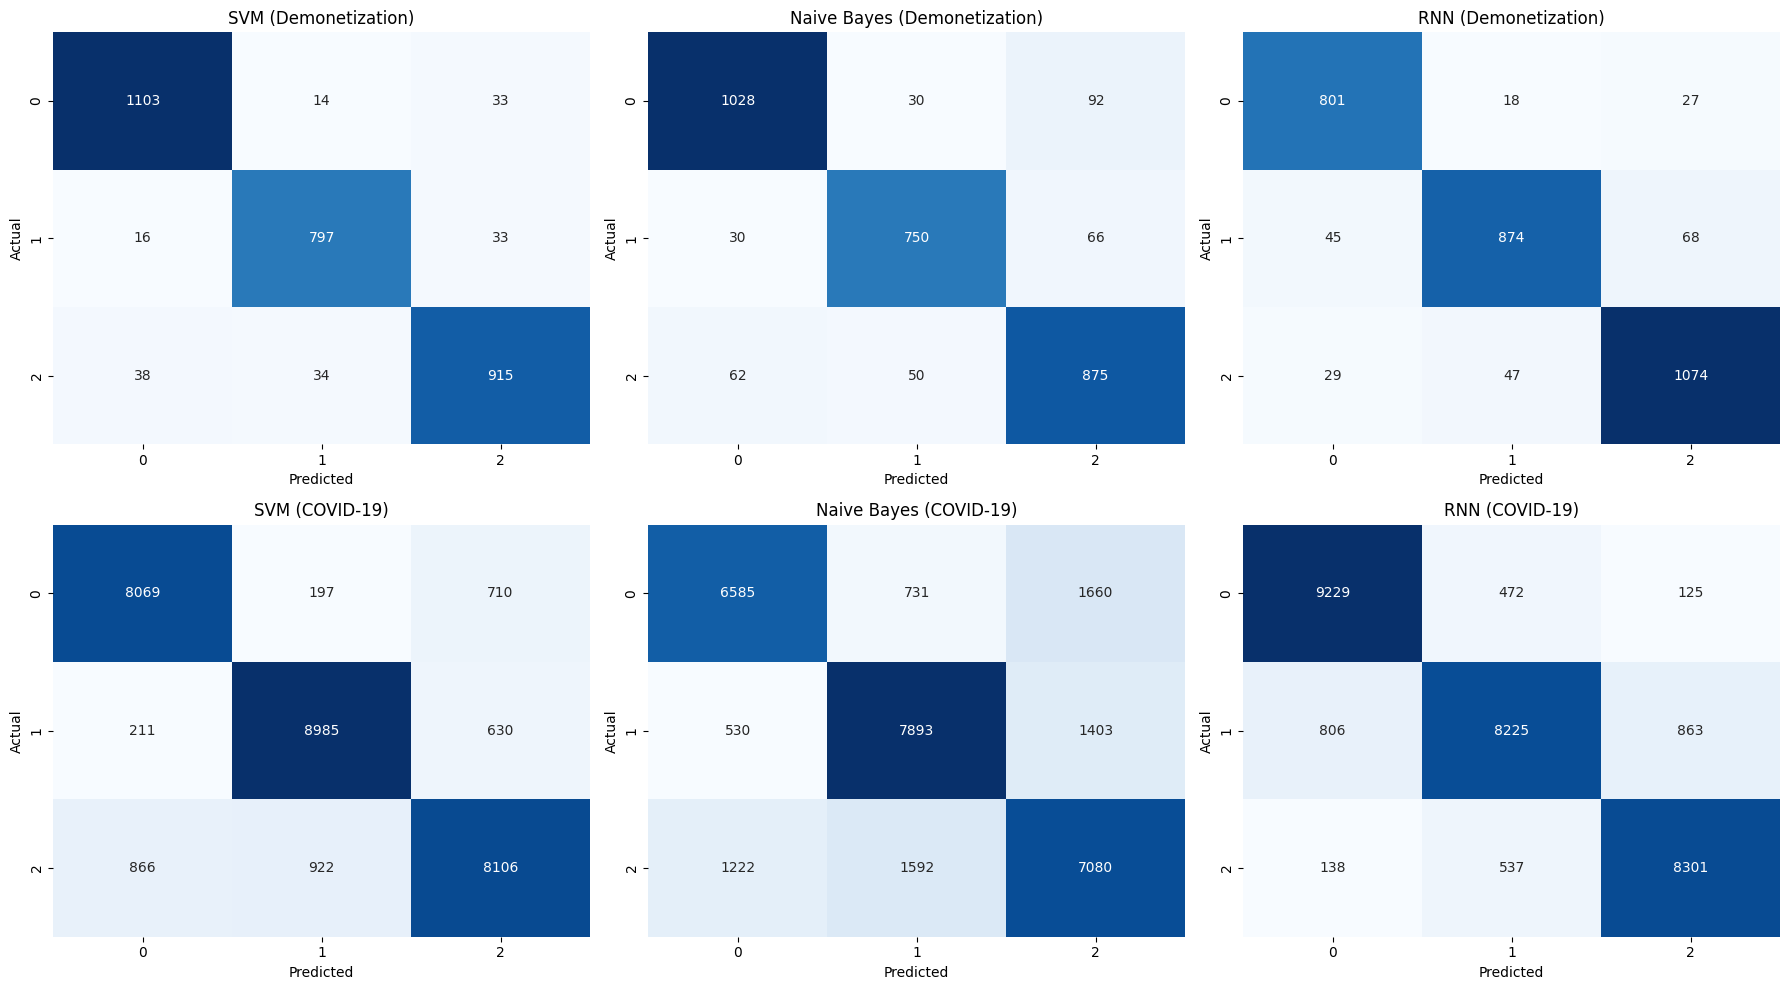

      Model        Dataset  Accuracy  Precision  Recall    F1  Error Rate
        SVM Demonetization     94.37      94.36   94.37 94.37        5.63
Naive Bayes Demonetization     88.94      89.04   88.94 88.96       11.06
        RNN Demonetization     92.16      92.18   92.16 92.14        7.84
        SVM       COVID-19     87.68      87.63   87.68 87.63       12.32
Naive Bayes       COVID-19     75.13      75.23   75.13 75.13       24.87
        RNN       COVID-19     89.75      89.73   89.75 89.69       10.25


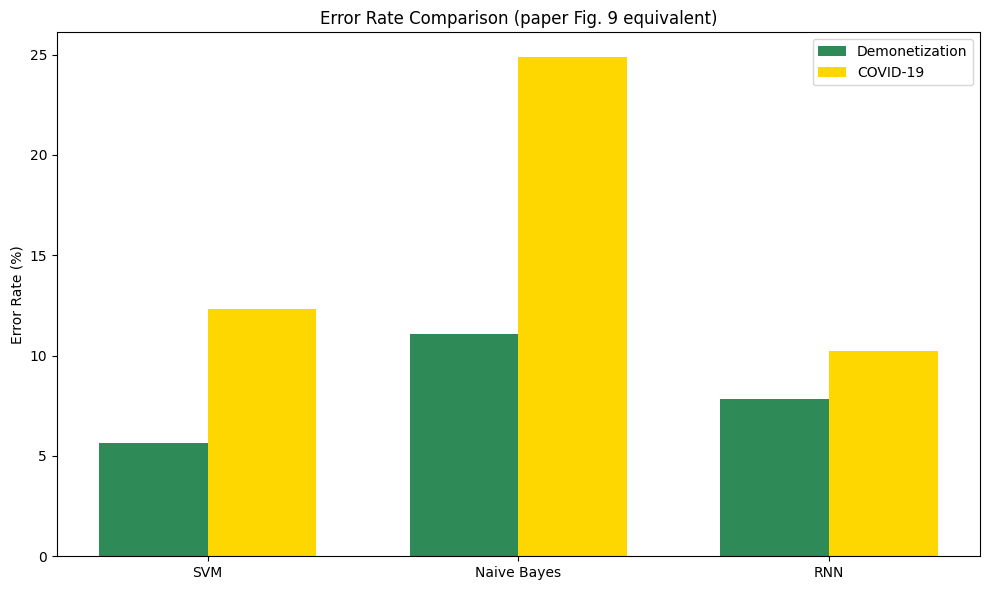


Training times (seconds):
  SVM (Demonetization): 0.76s
  Naive Bayes (Demonetization): 0.01s
  RNN (Demonetization): 14.84s
  SVM (COVID-19): 2.07s
  Naive Bayes (COVID-19): 0.21s
  RNN (COVID-19): 87.45s


In [16]:
# ============================================================
# Confusion matrices - all 6 models, visualized as heatmaps
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

configs = [
    (results_svm_demo, axes[0,0]), (results_nb_demo, axes[0,1]), (results_rnn_demo, axes[0,2]),
    (results_svm_covid, axes[1,0]), (results_nb_covid, axes[1,1]), (results_rnn_covid, axes[1,2])
]

for result, ax in configs:
    cm = result['confusion_matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(result['model'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

# ============================================================
# Build final summary table
# ============================================================
all_final_results = [
    results_svm_demo, results_nb_demo, results_rnn_demo,
    results_svm_covid, results_nb_covid, results_rnn_covid
]

final_summary = pd.DataFrame([{
    'Model': r['model'].split(' (')[0],
    'Dataset': r['model'].split('(')[1].replace(')', ''),
    'Accuracy': round(r['accuracy'], 2),
    'Precision': round(r['precision'], 2),
    'Recall': round(r['recall'], 2),
    'F1': round(r['f1'], 2),
} for r in all_final_results])

final_summary['Error Rate'] = round(100 - final_summary['Accuracy'], 2)
print(final_summary.to_string(index=False))

# ============================================================
# Error rate comparison graph
# ============================================================
models = ['SVM', 'Naive Bayes', 'RNN']
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(models))
width = 0.35

demo_err = [final_summary[(final_summary['Model']==m) & (final_summary['Dataset']=='Demonetization')]['Error Rate'].values[0] for m in models]
covid_err = [final_summary[(final_summary['Model']==m) & (final_summary['Dataset']=='COVID-19')]['Error Rate'].values[0] for m in models]

ax.bar(x - width/2, demo_err, width, label='Demonetization', color='seagreen')
ax.bar(x + width/2, covid_err, width, label='COVID-19', color='gold')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel('Error Rate (%)')
ax.set_title('Error Rate Comparison (paper Fig. 9 equivalent)')
ax.legend()
plt.tight_layout()
plt.show()

# ============================================================
# Training time comparison
# ============================================================
print("\nTraining times (seconds):")
for r in all_final_results:
    print(f"  {r['model']}: {r['train_time']:.2f}s")

       Dataset       Model  Paper Accuracy  Our Accuracy  Difference
Demonetization         SVM           92.25         94.37        2.12
Demonetization Naive Bayes           73.00         88.94       15.94
Demonetization         RNN           87.00         92.16        5.16
      COVID-19         SVM           70.66         87.68       17.02
      COVID-19 Naive Bayes           66.97         75.13        8.16
      COVID-19         RNN           69.34         89.75       20.41


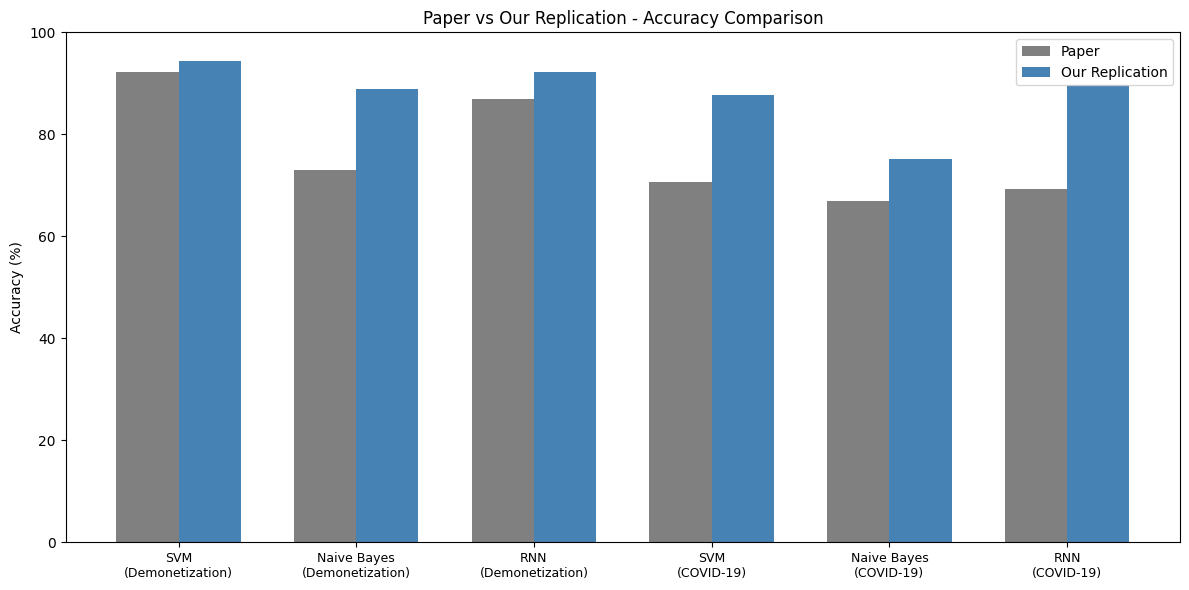

In [17]:
comparison_table = pd.DataFrame([
    {'Dataset': 'Demonetization', 'Model': 'SVM', 'Paper Accuracy': 92.25, 'Our Accuracy': 94.37, 'Difference': round(94.37-92.25, 2)},
    {'Dataset': 'Demonetization', 'Model': 'Naive Bayes', 'Paper Accuracy': 73.00, 'Our Accuracy': 88.94, 'Difference': round(88.94-73.00, 2)},
    {'Dataset': 'Demonetization', 'Model': 'RNN', 'Paper Accuracy': 87.00, 'Our Accuracy': 92.16, 'Difference': round(92.16-87.00, 2)},
    {'Dataset': 'COVID-19', 'Model': 'SVM', 'Paper Accuracy': 70.66, 'Our Accuracy': 87.68, 'Difference': round(87.68-70.66, 2)},
    {'Dataset': 'COVID-19', 'Model': 'Naive Bayes', 'Paper Accuracy': 66.97, 'Our Accuracy': 75.13, 'Difference': round(75.13-66.97, 2)},
    {'Dataset': 'COVID-19', 'Model': 'RNN', 'Paper Accuracy': 69.34, 'Our Accuracy': 89.75, 'Difference': round(89.75-69.34, 2)},
])

print(comparison_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(comparison_table))
width = 0.35

ax.bar(x - width/2, comparison_table['Paper Accuracy'], width, label='Paper', color='gray')
ax.bar(x + width/2, comparison_table['Our Accuracy'], width, label='Our Replication', color='steelblue')

ax.set_xticks(x)
ax.set_xticklabels([f"{row['Model']}\n({row['Dataset']})" for _, row in comparison_table.iterrows()], fontsize=9)
ax.set_ylabel('Accuracy (%)')
ax.set_title('Paper vs Our Replication - Accuracy Comparison')
ax.legend()
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()